# L1 · Dane transportowe w Pythonie: sieć OSM, rozkład GTFS i Generalny Pomiar Ruchu 2025

**Sztuczna inteligencja w przetwarzaniu geodanych** · Geoinformatyka, I stopień · laboratorium 1
⏱️ ok. 90 minut + zadanie dodatkowe dla chętnych

## Po co te zajęcia

Przez cały semestr pracujemy na jednym obszarze testowym – **Krakowie** – i z każdym laboratorium dokładamy nową warstwę danych albo nowy model. Dziś budujemy fundament: wczytujemy trzy podstawowe źródła danych transportowych i zapisujemy je w jednym pliku GeoPackage, który otworzysz w QGIS i wykorzystasz na kolejnych zajęciach.

| Źródło | Co zawiera | Do czego się przyda |
|---|---|---|
| **OpenStreetMap (OSM)** | sieć ulic z kategorią drogi, kierunkami ruchu, ograniczeniami prędkości | graf sieci, czasy przejazdu, cechy odcinków (L2) |
| **GTFS ZTP Kraków** | rozkład jazdy autobusów i tramwajów | dostępność transportu zbiorowego |
| **Generalny Pomiar Ruchu 2025 (GDDKiA)** | średni dobowy ruch roczny (SDRR) na odcinkach dróg krajowych | etykieta do modelu natężenia ruchu (W2, L5) |

**Po zajęciach będziesz umieć:**
1. pracować w notatniku Colab i używać bibliotek **pandas** i **GeoPandas**,
2. przeliczać dane między układami współrzędnych i wyjaśnić, dlaczego długości liczymy w metrach (EPSG:2180),
3. pobrać sieć drogową z OSM i ocenić kompletność jej atrybutów,
4. odczytać rozkład jazdy GTFS i policzyć odjazdy z przystanków w wybranym dniu,
5. wczytać wyniki GPR 2025 i pokazać ruch na mapie,
6. łączyć warstwy złączeniem przestrzennym i zapisywać wyniki do GeoPackage.

## Jak pracować z tym notatnikiem

1. **Zapisz własną kopię:** *Plik → Zapisz kopię na Dysku* (*File → Save a copy in Drive*). Pracuj tylko na kopii.
2. **Uruchamiaj komórki po kolei**, od góry: kliknij komórkę i naciśnij **Shift+Enter**. Kolejność ma znaczenie, bo kolejne komórki korzystają z wyników poprzednich.
3. Komórki oznaczone **`# TODO`** uzupełniasz sam lub sama: w miejscu `...` wpisz kod. Reszta kodu jest gotowa – przeczytaj ją, bo z niej się uczysz. Błąd ze słowem `ellipsis` oznacza, że w kodzie została jeszcze luka `...`.
4. Pod każdym zadaniem jest **komórka sprawdzająca**. ✅ oznacza poprawny wynik, ❌ – coś do poprawy (komunikat podpowiada, co).
5. **💡 Podpowiedzi** rozwijasz kliknięciem. Najpierw spróbuj bez nich.
6. Gdy coś się „zawiesi” albo pomylisz kolejność: *Środowisko wykonawcze → Uruchom ponownie sesję* (*Runtime → Restart session*), a potem kliknij komórkę, na której skończyłeś/aś, i naciśnij **Ctrl+F8** – Colab uruchomi wszystkie komórki powyżej.
7. Odpowiedzi na pytania otwarte wpisz w komórkach **✍️ Twoja odpowiedź** (kliknij dwukrotnie, aby edytować).

> 🧭 **Konwencja nazw:** zmienne nazywamy po polsku (`przystanki`, `krawedzie`), a funkcje bibliotek mają nazwy angielskie (`to_crs`, `groupby`). Gdy nie wiesz, co robi funkcja, wpisz w nowej komórce `help(nazwa_funkcji)` albo postaw kursor w nawiasie i naciśnij **Ctrl+Spacja**.

## Punktacja i oddanie pracy

| Zadanie | Temat | Punkty |
|---|---|---|
| 1.1 | Odległość w stopniach i w metrach | 2 |
| 2.1 | Powierzchnia miasta | 1 |
| 2.2 | Graf w układzie EPSG:2180 i tabele węzłów oraz krawędzi | 2 |
| 2.3 | Długość sieci: graf skierowany a nieskierowany | 2 |
| 2.4 | Kompletność atrybutów OSM | 3 |
| 3.1 | Przystanki jako warstwa geoprzestrzenna | 2 |
| 3.2 | Liczba odjazdów z przystanków | 3 |
| 4.1 | Rozpoznanie kolumn w danych GPR | 2 |
| 4.2 | Odcinki GPR w województwie i w mieście | 2 |
| 5.1 | Najbliższa ulica dla każdego przystanku | 2 |
| 6.1 | Zapis do GeoPackage | 1 |
| 8 | Pytania do przemyślenia (3 × 1 pkt) | 3 |
| | **Razem** | **25** |
| 7 | Zadanie dodatkowe: BDOT10k a OSM | +2 |

**Oddajesz** (na platformie wskazanej przez prowadzącego):
1. notatnik z wynikami: *Plik → Pobierz → Pobierz plik .ipynb*, *File → Download → Download .ipynb*, nazwa `L1_Nazwisko_Imie.ipynb`,
2. plik `L1_krakow.gpkg` z folderu `GeoAI_transport` na Twoim Dysku Google.

---
## 0. Przygotowanie środowiska (ok. 5 min)

Colab to komputer w chmurze Google, który uruchamia kod Pythona w Twojej przeglądarce. Każda sesja startuje „czysta”: biblioteki spoza standardowego zestawu i pobrane dane trzeba za każdym razem przygotować od nowa, a po zamknięciu karty pliki w folderze `/content` znikają. Dlatego:

* pierwsza komórka instaluje bibliotekę **OSMnx** (pobieranie i analiza sieci z OpenStreetMap),
* wyniki zapisujemy na **Dysku Google** – wtedy przetrwają do kolejnych zajęć.

Uruchom po kolei pięć komórek poniżej. Instalacja trwa do minuty; czerwone ostrzeżenia `pip` o wersjach innych pakietów możesz zignorować.

In [1]:
# Instalacja bibliotek, których nie ma w Colabie (ok. 30–60 s).
# OSMnx pobiera dane z OpenStreetMap i zamienia je na graf sieci drogowej.
!pip install -q "osmnx==2.1.1" mapclassify


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install geopandas
!pip install shapely
!pip install networkx
!pip install requests
!pip install IPython


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, json, time, zipfile, warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import networkx as nx
import osmnx as ox
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Kolory wykresów: stała kolejność barw dla kategorii i jedna barwa (od jasnej do ciemnej) dla wielkości
KOLORY = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SZARY = "#c9cdd2"
NIEBIESKI = LinearSegmentedColormap.from_list(
    "niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

print("geopandas", gpd.__version__, "| osmnx", ox.__version__, "| networkx", nx.__version__,
      "| pandas", pd.__version__)

geopandas 1.2.0 | osmnx 2.1.1 | networkx 3.7 | pandas 2.3.3


**Ustawienia obszaru testowego.** Nazwy miejsc są takie, jak w wyszukiwarce OpenStreetMap (Nominatim). `SKROT` to krótka nazwa używana w nazwach plików. Adresy `GTFS` wskazują rozkłady jazdy publikowane przez Zarząd Transportu Publicznego w Krakowie.

In [3]:
# Obszar testowy całego semestru. Zmieniaj tylko wtedy, gdy prowadzący poda inne miasto.
MIASTO = "Kraków, Polska"                            # @param {type:"string"}
WOJEWODZTWO = "województwo małopolskie, Polska"      # @param {type:"string"}
SKROT = "krakow"                                     # @param {type:"string"}

# Rozkłady jazdy GTFS (Zarząd Transportu Publicznego w Krakowie)
GTFS = {
    "A": "https://gtfs.ztp.krakow.pl/GTFS_KRK_A.zip",   # autobusy MPK
    "T": "https://gtfs.ztp.krakow.pl/GTFS_KRK_T.zip",   # tramwaje MPK
    "M": "https://gtfs.ztp.krakow.pl/GTFS_KRK_M.zip",   # autobusy Mobilis
}
# Generalny Pomiar Ruchu 2025 (GDDKiA): odcinki pomiarowe dróg krajowych z wynikami, plik SHP w ZIP
GPR_SHP_URL = "https://www.gov.pl/attachment/7f8ca805-e384-4802-bf10-d36538e6ef84"

**Dysk Google.** Po uruchomieniu komórki Colab poprosi o zgodę na dostęp do Dysku. Pliki trafią do folderu `GeoAI_transport` w *Mój dysk*. Jeśli nie chcesz używać Dysku, ustaw `UZYJ_DYSKU = False` – wtedy przed zamknięciem notatnika pobierz plik `.gpkg` ręcznie (panel 📁 po lewej stronie).

In [4]:
# Pliki zapisujemy na Dysku Google, bo wyniki L1 będą potrzebne na kolejnych zajęciach.
# Colab poprosi o zgodę na dostęp do Dysku – zaakceptuj ją.
UZYJ_DYSKU = False  # @param {type:"boolean"}

FOLDER = Path(os.environ.get("GEOAI_FOLDER", "/content/dane_geoai"))
if UZYJ_DYSKU and "GEOAI_FOLDER" not in os.environ:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        FOLDER = Path("/content/drive/MyDrive/GeoAI_transport")
    except Exception as e:
        print("Nie udało się podłączyć Dysku Google, pliki zapiszę tylko w tej sesji:", e)
FOLDER.mkdir(parents=True, exist_ok=True)
POBRANE = FOLDER / "pobrane"
POBRANE.mkdir(exist_ok=True)
print("Folder roboczy:", FOLDER)

Folder roboczy: \content\dane_geoai


**Funkcje pomocnicze.** Poniższa komórka definiuje kilka funkcji, z których będziemy korzystać:
`sprawdz` (komórki sprawdzające), `pobierz` (pobieranie plików z powtórzeniem przy błędzie), `z_osm` (pobieranie z OSM z serwerami zapasowymi), `pierwszy` i `liczba` (porządkowanie atrybutów OSM), `do_zapisu` (przygotowanie tabel do GeoPackage) i `opisz_mape` (wspólny wygląd map). Uruchom ją; nie musisz jej zmieniać.

In [5]:
# ---------- Funkcje pomocnicze: uruchom tę komórkę, nie musisz jej zmieniać ----------

WYNIKI_SPRAWDZEN = {}

def sprawdz(zadanie, opis, warunek, podpowiedz=""):
    """Sprawdza warunek i wypisuje ✅ albo ❌ z podpowiedzią. `warunek` to zwykle funkcja lambda."""
    try:
        ok = bool(warunek() if callable(warunek) else warunek)
        blad = ""
    except Exception as e:
        ok, blad = False, f"{type(e).__name__}: {e}"
    print(f"{'✅' if ok else '❌'} [{zadanie}] {opis}")
    if not ok:
        if blad:
            print(f"   ⚠️ Błąd podczas sprawdzania: {blad}")
        if podpowiedz:
            print(f"   👉 {podpowiedz}")
    WYNIKI_SPRAWDZEN[(zadanie, opis)] = ok


def pobierz(url, plik, min_bajtow=1000):
    """Pobiera plik z internetu tylko raz; przy kolejnym uruchomieniu używa kopii z dysku."""
    plik = Path(plik)
    if plik.exists() and plik.stat().st_size >= min_bajtow:
        print(f"Używam pobranego wcześniej pliku {plik.name} ({plik.stat().st_size / 1e6:.1f} MB)")
        return plik
    print(f"Pobieram {url}")
    ostatni = None
    for proba in range(3):
        try:
            with requests.get(url, stream=True, timeout=120,
                              headers={"User-Agent": "GeoAI-transport-lab (zajecia dydaktyczne)"}) as r:
                r.raise_for_status()
                czesc = plik.with_name(plik.name + ".czesc")
                with open(czesc, "wb") as f:
                    for kawalek in r.iter_content(chunk_size=1 << 20):
                        f.write(kawalek)
            czesc.replace(plik)
            print(f"Gotowe: {plik.name} ({plik.stat().st_size / 1e6:.1f} MB)")
            return plik
        except Exception as e:
            ostatni = e
            print(f"Próba {proba + 1} nieudana: {e}")
            time.sleep(5 * (proba + 1))
    raise RuntimeError(f"Nie udało się pobrać {url}. Sprawdź połączenie i spróbuj ponownie za kilka minut.") from ostatni


# Serwery Overpass API, z których OSMnx pobiera dane OSM (główny i dwa zapasowe)
SERWERY_OVERPASS = ["https://overpass-api.de/api", "https://overpass.private.coffee/api",
                    "https://maps.mail.ru/osm/tools/overpass/api"]
ox.settings.use_cache = True
ox.settings.cache_folder = str(FOLDER / "cache_osm")
ox.settings.requests_timeout = 300
ox.settings.log_console = False

def z_osm(funkcja, *args, **kwargs):
    """Wywołuje funkcję OSMnx; gdy serwer nie odpowiada, próbuje kolejnego."""
    ostatni = None
    for i, url in enumerate(SERWERY_OVERPASS):
        ox.settings.overpass_url = url
        ox.settings.overpass_rate_limit = (i == 0)   # tylko serwer główny ma limit zapytań
        try:
            return funkcja(*args, **kwargs)
        except Exception as e:
            ostatni = e
            print(f"Serwer {url} nie odpowiedział ({type(e).__name__}: {str(e)[:120]}). Próbuję następnego…")
            time.sleep(3)
    raise RuntimeError("Serwery OSM nie odpowiadają. Odczekaj kilka minut i uruchom komórkę ponownie.") from ostatni


def pierwszy(x):
    """OSMnx przy upraszczaniu grafu czasem zapisuje atrybut jako listę, np. ['primary', 'secondary'].
    Funkcja zwraca pierwszy element listy albo samą wartość."""
    if isinstance(x, (list, tuple)):
        return x[0] if len(x) else None
    return x


def liczba(x):
    """Zamienia napis typu '50', '2;3' albo '50 mph' na pierwszą występującą liczbę; inaczej NaN."""
    x = pierwszy(x)
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    m = re.search(r"\d+(?:[.,]\d+)?", str(x))
    return float(m.group().replace(",", ".")) if m else np.nan


def do_zapisu(gdf):
    """GeoPackage nie przyjmuje list w kolumnach – zamieniamy je na napisy."""
    gdf = gdf.copy()
    for k in gdf.columns:
        if k != gdf.geometry.name and gdf[k].dtype == object:
            gdf[k] = gdf[k].apply(lambda v: ";".join(map(str, v)) if isinstance(v, (list, tuple, set)) else v)
    return gdf


def opisz_mape(ax, tytul, zrodlo="Dane: © autorzy OpenStreetMap"):
    """Wspólny wygląd map: tytuł, bez osi, źródło danych w rogu."""
    ax.set_title(tytul, loc="left", fontsize=12)
    ax.set_axis_off()
    ax.text(0.99, 0.01, zrodlo, transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="#52514e")


def podsumowanie():
    """Zestawienie wszystkich sprawdzeń z tego notatnika."""
    if not WYNIKI_SPRAWDZEN:
        print("Nie uruchomiono jeszcze żadnej komórki sprawdzającej.")
        return
    tab = pd.DataFrame([(z, o, "✅" if ok else "❌") for (z, o), ok in WYNIKI_SPRAWDZEN.items()],
                       columns=["zadanie", "sprawdzenie", "wynik"])
    display(tab)
    print(f"Zaliczone sprawdzenia: {(tab['wynik'] == '✅').sum()} z {len(tab)}")


---
## 1. Python i geodane w pigułce (ok. 15 min)

### 1.0. Minimum Pythona, którego dziś użyjesz

Jeśli Python jest dla Ciebie nowy albo dawno go nie używałeś/aś, przeczytaj komórkę poniżej i uruchom ją. To wszystkie konstrukcje języka, które pojawią się w zadaniach.

In [6]:
# Zmienna: nazwa = wartość
miasto = "Kraków"
ludnosc = 800_653            # podkreślenia w liczbach ułatwiają czytanie

# f-napis: wstawianie wartości do tekstu; :, dodaje separator tysięcy, :.1f – jedno miejsce po przecinku
print(f"{miasto} ma {ludnosc:,} mieszkańców, czyli {ludnosc / 1e6:.1f} mln")

# Lista (kolejność ma znaczenie, numeracja od 0) i słownik (klucz -> wartość)
linie = [52, 4, 8]
print("pierwsza linia:", linie[0], "| liczba linii:", len(linie))
rozklady = {"A": "autobusy", "T": "tramwaje"}
print("T to:", rozklady["T"])

# Pętla po elementach listy i po parach klucz-wartość słownika
for nr in linie:
    print("linia", nr)
for kod, opis in rozklady.items():
    print(kod, "=", opis)

# Funkcja: def nazwa(argumenty): ... return wynik
def predkosc_kmh(droga_m, czas_s):
    return droga_m / czas_s * 3.6

print(f"{predkosc_kmh(1000, 120):.0f} km/h")

# Wywołanie z argumentami nazwanymi – kolejność nie ma znaczenia
print(predkosc_kmh(czas_s=60, droga_m=500))

# Funkcja zwracająca dwie wartości – rozpakowanie do dwóch zmiennych
def min_max(lista):
    return min(lista), max(lista)

najmniejsza, najwieksza = min_max(linie)
print(najmniejsza, najwieksza)

Kraków ma 800,653 mieszkańców, czyli 0.8 mln
pierwsza linia: 52 | liczba linii: 3
T to: tramwaje
linia 52
linia 4
linia 8
A = autobusy
T = tramwaje
30 km/h
30.000000000000004
4 52


W zadaniach luki oznaczamy `...`. To poprawny obiekt Pythona (*Ellipsis*), więc komórka z luką się uruchomi, ale dalsze obliczenia zakończą się błędem ze słowem `ellipsis` – to znak, że luka czeka na uzupełnienie.

### 1.1. Tabela danych: `pandas.DataFrame`

**DataFrame** to tabela: kolumny mają nazwy, wiersze – indeks. Najważniejsze operacje, których użyjemy dziś:

| Co chcesz zrobić | Kod |
|---|---|
| wybrać kolumnę | `df["nazwa"]` |
| wybrać kilka kolumn | `df[["nazwa", "lat"]]` |
| wybrać wiersze spełniające warunek | `df[df["lat"] > 50.06]` |
| dodać kolumnę | `df["nowa"] = df["a"] * 2` |
| policzyć sumę, średnią, medianę | `df["a"].sum()`, `.mean()`, `.median()` |
| policzyć coś w grupach | `df.groupby("rodzaj")["a"].sum()` |
| połączyć dwie tabele po kluczu | `df.merge(inna, on="klucz", how="left")` |
| policzyć, ile razy występuje każda wartość | `df["rodzaj"].value_counts()` |

Uruchom przykład i porównaj kod z wynikiem.

In [7]:
# Przykład: zwykła tabela pandas
miejsca = pd.DataFrame({
    "nazwa":  ["Rynek Główny", "Kraków Główny (dworzec)", "Wawel", "AGH (budynek A-0)"],
    "lat":    [50.0617, 50.0677, 50.0540, 50.0647],     # szerokość geograficzna (stopnie)
    "lon":    [19.9372, 19.9474, 19.9354, 19.9234],     # długość geograficzna (stopnie)
    "rodzaj": ["plac", "dworzec", "zabytek", "uczelnia"],
})
display(miejsca)

print("Nazwy:", miejsca["nazwa"].tolist())
print("Miejsca na północ od 50,06°N:")
display(miejsca[miejsca["lat"] > 50.06])

miejsca["opis"] = miejsca["nazwa"] + " (" + miejsca["rodzaj"] + ")"
display(miejsca[["opis"]])

,nazwa,lat,lon,rodzaj
0,Rynek Główny,50.0617,19.9372,plac
1,Kraków Główny (dworzec),50.0677,19.9474,dworzec
2,Wawel,50.0540,19.9354,zabytek
3,AGH (budynek A-0),50.0647,19.9234,uczelnia


Nazwy: ['Rynek Główny', 'Kraków Główny (dworzec)', 'Wawel', 'AGH (budynek A-0)']
Miejsca na północ od 50,06°N:


,nazwa,lat,lon,rodzaj
0,Rynek Główny,50.0617,19.9372,plac
1,Kraków Główny (dworzec),50.0677,19.9474,dworzec
3,AGH (budynek A-0),50.0647,19.9234,uczelnia


,opis
0,Rynek Główny (plac)
1,Kraków Główny (dworzec) (dworzec)
2,Wawel (zabytek)
3,AGH (budynek A-0) (uczelnia)


### 1.2. Tabela z geometrią: `geopandas.GeoDataFrame` i układy współrzędnych

**GeoDataFrame** to DataFrame z dodatkową kolumną `geometry` (punkt, linia, poligon) i **układem współrzędnych** (CRS, *coordinate reference system*), zapisanym kodem EPSG. W tym przedmiocie używamy głównie dwóch układów:

| Kod | Nazwa | Jednostka | Do czego |
|---|---|---|---|
| **EPSG:4326** | WGS 84 (GPS, OSM, GTFS) | stopnie | zapis współrzędnych, wymiana danych |
| **EPSG:2180** | PL-1992 (układ państwowy) | metry | **odległości, długości, pola, bufory** w Polsce |

Dlaczego nie liczymy w stopniach? Stopień szerokości geograficznej to zawsze ok. 111 km, ale stopień długości geograficznej skraca się ku biegunom: na szerokości Krakowa (50°N) to tylko ok. 71,6 km. „Odległość” policzona wprost na stopniach miesza więc dwie różne jednostki i nie jest żadną odległością. Zasada na cały semestr: **przed każdym pomiarem przelicz dane do EPSG:2180** metodą `to_crs("EPSG:2180")`.

⚠️ W `gpd.points_from_xy(x, y)` najpierw podajemy **x = długość (lon)**, potem **y = szerokość (lat)**. Zamiana kolejności to jeden z najczęstszych błędów – punkty z Krakowa lądują wtedy na Półwyspie Arabskim (szerokość 19,9°, długość 50,1°).

Układ: EPSG:4326


,nazwa,geometry
0,Rynek Główny,POINT (19.9372 50.0617)
1,Kraków Główny (dworzec),POINT (19.9474 50.0677)
2,Wawel,POINT (19.9354 50.054)
3,AGH (budynek A-0),POINT (19.9234 50.0647)


Układ po przeliczeniu: EPSG:2180


,nazwa,geometry
0,Rynek Główny,POINT (567059.73 244247.052)
1,Kraków Główny (dworzec),POINT (567781.105 244923.155)
2,Wawel,POINT (566941.649 243389.586)
3,AGH (budynek A-0),POINT (566068.189 244568.208)


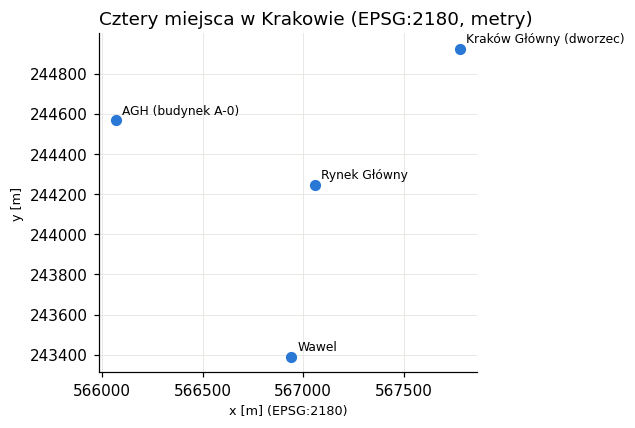

In [8]:
punkty = gpd.GeoDataFrame(
    miejsca,
    geometry=gpd.points_from_xy(miejsca["lon"], miejsca["lat"]),  # x = lon, y = lat
    crs="EPSG:4326",
)
print("Układ:", punkty.crs)
display(punkty[["nazwa", "geometry"]])

punkty_m = punkty.to_crs("EPSG:2180")      # te same punkty w metrach
print("Układ po przeliczeniu:", punkty_m.crs)
display(punkty_m[["nazwa", "geometry"]])

ax = punkty_m.plot(color=KOLORY[0], markersize=40, figsize=(6, 4))
for x, y, n in zip(punkty_m.geometry.x, punkty_m.geometry.y, punkty_m["nazwa"]):
    ax.annotate(n, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.ticklabel_format(useOffset=False, style="plain")
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.set_xlabel("x [m] (EPSG:2180)")
ax.set_ylabel("y [m]")
ax.set_title("Cztery miejsca w Krakowie (EPSG:2180, metry)", loc="left");

### Zadanie 1.1 (2 pkt) · Odległość w stopniach i w metrach

Geometrie mają metodę `distance`, np. `punkt_a.distance(punkt_b)`. Wynik jest w jednostkach układu, w którym są geometrie.

**Do zrobienia:**
1. Komórka liczy już odległość Rynek Główny – dworzec Kraków Główny w układzie EPSG:4326 (zmienna `odleglosc_stopnie`).
2. Policz tę samą odległość w metrach, korzystając z ramki `punkty_m` (EPSG:2180). Wynik zapisz w zmiennej `odleglosc_m`.

<details><summary>💡 Podpowiedź</summary>

Skopiuj dwa pierwsze wiersze kodu i zamień w nich `punkty` na `punkty_m`. Pojedynczą geometrię z ramki wyciągasz przez `.geometry.iloc[0]`.
</details>

In [9]:
rynek = punkty[punkty["nazwa"] == "Rynek Główny"].geometry.iloc[0]
dworzec = punkty[punkty["nazwa"] == "Kraków Główny (dworzec)"].geometry.iloc[0]
odleglosc_stopnie = rynek.distance(dworzec)

# TODO: ta sama odległość w metrach (ramka punkty_m)
rynek_m = punkty_m[punkty_m["nazwa"] == "Rynek Główny"].geometry.iloc[0]
dworzec_m = punkty_m[punkty_m["nazwa"] == "Kraków Główny (dworzec)"].geometry.iloc[0]
odleglosc_m = rynek_m.distance(dworzec_m)

print(f"EPSG:4326: {odleglosc_stopnie:.5f} (stopnie – to nie jest odległość!)")
print(f"EPSG:2180: {odleglosc_m:.0f} m")

EPSG:4326: 0.01183 (stopnie – to nie jest odległość!)
EPSG:2180: 989 m


In [10]:
sprawdz("Z1.1", "odległość w metrach policzona w EPSG:2180",
        lambda: 900 < odleglosc_m < 1100,
        "Wynik powinien mieć ok. 1 km. Czy używasz ramki punkty_m, a nie punkty?")
sprawdz("Z1.1", "rynek_m i dworzec_m to punkty z ramki punkty_m (współrzędne w metrach)",
        lambda: isinstance(rynek_m, shapely.Point) and isinstance(dworzec_m, shapely.Point)
        and min(rynek_m.x, rynek_m.y, dworzec_m.x, dworzec_m.y) > 100_000,
        "Pojedynczy punkt z ramki: punkty_m[punkty_m['nazwa'] == 'Rynek Główny'].geometry.iloc[0]")

✅ [Z1.1] odległość w metrach policzona w EPSG:2180
✅ [Z1.1] rynek_m i dworzec_m to punkty z ramki punkty_m (współrzędne w metrach)


---
## 2. Sieć drogowa z OpenStreetMap (ok. 25 min)

**OpenStreetMap (OSM)** to otwarta mapa świata tworzona przez wolontariuszy. Każda droga to obiekt z **tagami** (para *klucz = wartość*). Najważniejsze dla nas:

| Tag | Znaczenie | Przykładowe wartości |
|---|---|---|
| `highway` | klasa drogi | `motorway` (autostrada), `trunk` (droga ekspresowa, ważna krajowa), `primary` (główna, zwykle krajowa), `secondary` (zwykle wojewódzka), `tertiary` (zbiorcza, zwykle powiatowa), `residential` (osiedlowa), `living_street` (strefa zamieszkania), `unclassified` (lokalna), `service` (dojazdowa); końcówka `_link` oznacza łącznicę (zjazd) |
| `maxspeed` | ograniczenie prędkości | `50`, `30`, `PL:urban` (domyślne w terenie zabudowanym) |
| `lanes` | liczba pasów ruchu | `1`, `2`, `3` |
| `oneway` | ulica jednokierunkowa | `yes`, `no` |
| `name`, `ref` | nazwa, numer drogi | `Aleja Jana Pawła II`, `DK79` |

Tagi uzupełniają wolontariusze, więc **kompletność bywa różna** – za chwilę to zmierzymy.

**Biblioteka OSMnx** pobiera drogi z serwera *Overpass API* i zamienia je na **graf**:
* **węzły** (*nodes*) to skrzyżowania i końce ulic,
* **krawędzie** (*edges*) to odcinki ulic między węzłami, z atrybutami z tagów OSM i długością `length` w metrach,
* graf jest **skierowany** (`MultiDiGraph`): ulica dwukierunkowa to dwie krawędzie, A→B i B→A; ulica jednokierunkowa – jedna.

`network_type="drive"` oznacza drogi dostępne dla samochodów (bez chodników, ścieżek rowerowych i dróg prywatnych).

📜 Dane OSM są na licencji ODbL: na mapach podpisujemy źródło „© autorzy OpenStreetMap”.

Zacznijmy od granicy miasta. `ox.geocode_to_gdf` wyszukuje nazwę w Nominatim (wyszukiwarka OSM) i zwraca poligon jako GeoDataFrame.

,display_name,geometry
0,"Krakow, Lesser Poland Voivodeship, Poland","POLYGON ((19.79224 50.0118, 19.79238 50.01104,..."


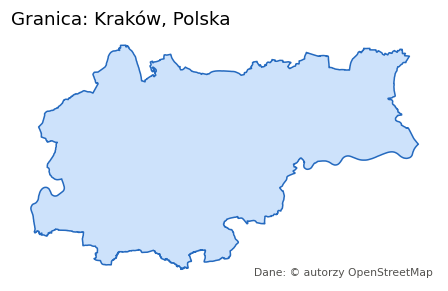

In [11]:
granica = z_osm(ox.geocode_to_gdf, MIASTO)
granica_m = granica.to_crs("EPSG:2180")
display(granica[["display_name", "geometry"]])

fig, ax = plt.subplots(figsize=(5, 5))
granica_m.plot(ax=ax, color="#cde2fb", edgecolor="#256abf")
opisz_mape(ax, f"Granica: {MIASTO}")

### Zadanie 2.1 (1 pkt) · Powierzchnia miasta

Atrybut `.area` zwraca pole każdej geometrii w jednostkach układu (w EPSG:2180 – w m²). 1 km² = 1 000 000 m².

**Do zrobienia:** policz powierzchnię miasta w km² i zapisz ją w zmiennej `pole_km2` (jedna liczba, nie tabela).

<details><summary>💡 Podpowiedź</summary>

`granica_m.area` to seria z jedną wartością; wyciągnij ją przez `.iloc[0]` i podziel przez `1e6`.
</details>

In [20]:
# TODO: powierzchnia miasta w km²
pole_km2 = granica_m.geometry.iloc[0].area / 1e6
print(f"Powierzchnia: {pole_km2:.1f} km²")

Powierzchnia: 326.4 km²


In [19]:
sprawdz("Z2.1", "pole w km² ma sensowną wartość",
        lambda: 1 < float(pole_km2) < 5000,
        "Czy liczysz pole w ramce granica_m (EPSG:2180) i dzielisz przez 1e6? Kraków ma ok. 327 km².")

✅ [Z2.1] pole w km² ma sensowną wartość


**Pobieramy sieć drogową.** Komórka poniżej trwa zwykle 1–3 minuty: OSMnx wysyła zapytanie do serwera, buduje graf i upraszcza go (łączy fragmenty ulic między skrzyżowaniami w jedną krawędź). Gdy serwer jest przeciążony, funkcja `z_osm` spróbuje serwera zapasowego. Wynik trafia do pamięci podręcznej na Dysku, więc ponowne uruchomienie jest szybkie.

In [22]:
t0 = time.time()
G = z_osm(ox.graph_from_place, MIASTO, network_type="drive")
print(f"Pobrano w {time.time() - t0:.0f} s: {G.number_of_nodes():,} węzłów i {G.number_of_edges():,} krawędzi")
print("Układ współrzędnych grafu:", G.graph["crs"])

Pobrano w 101 s: 9,853 węzłów i 21,596 krawędzi
Układ współrzędnych grafu: epsg:4326


### Zadanie 2.2 (2 pkt) · Graf w metrach i tabele węzłów oraz krawędzi

Graf z OSMnx ma współrzędne w stopniach (EPSG:4326). Do pomiarów przeliczamy cały graf funkcją `ox.project_graph(G, to_crs="EPSG:2180")`, a potem zamieniamy go na dwie ramki GeoDataFrame funkcją `ox.graph_to_gdfs(graf)`, która zwraca parę: **(węzły, krawędzie)**.

**Do zrobienia:**
1. Przelicz graf `G` do EPSG:2180 i zapisz wynik w `G_p`.
2. Zamień `G_p` na dwie ramki: `wezly` i `krawedzie`.

<details><summary>💡 Podpowiedź</summary>

Funkcja zwracająca dwie wartości: `a, b = funkcja(argument)`.
</details>

In [23]:
# TODO 1: graf w EPSG:2180
G_p = ox.project_graph(G, to_crs="EPSG:2180")

# TODO 2: ramki węzłów i krawędzi
wezly, krawedzie = ox.graph_to_gdfs(G_p, nodes=True, edges=True)

print(len(wezly), "węzłów,", len(krawedzie), "krawędzi; układ:", krawedzie.crs)

9853 węzłów, 21596 krawędzi; układ: EPSG:2180


In [24]:
sprawdz("Z2.2", "graf G_p jest w EPSG:2180",
        lambda: str(G_p.graph["crs"]).upper().endswith("2180"),
        "Użyj ox.project_graph(G, to_crs='EPSG:2180').")
sprawdz("Z2.2", "ramka krawędzi ma układ EPSG:2180 i tyle wierszy, ile krawędzi grafu",
        lambda: krawedzie.crs.to_epsg() == 2180 and len(krawedzie) == G.number_of_edges())
sprawdz("Z2.2", "ramka węzłów ma tyle wierszy, ile węzłów grafu",
        lambda: len(wezly) == G.number_of_nodes())

✅ [Z2.2] graf G_p jest w EPSG:2180
✅ [Z2.2] ramka krawędzi ma układ EPSG:2180 i tyle wierszy, ile krawędzi grafu
✅ [Z2.2] ramka węzłów ma tyle wierszy, ile węzłów grafu


Obejrzyj kilka krawędzi. Indeks ramki to trójka **(u, v, key)**: węzeł początkowy, końcowy i numer krawędzi równoległej. Zauważ, że niektóre wartości są **listami** (np. `['primary', 'secondary']`): OSMnx łączy kilka obiektów OSM w jedną krawędź i zachowuje wszystkie wartości. Funkcja pomocnicza `pierwszy` bierze pierwszą z nich – tak powstaje kolumna `klasa`.

In [25]:
for kol in ["name", "maxspeed", "lanes", "oneway"]:        # na wypadek, gdyby w danych nie było któregoś tagu
    if kol not in krawedzie.columns:
        krawedzie[kol] = np.nan
krawedzie["klasa"] = krawedzie["highway"].apply(pierwszy)
display(krawedzie[["highway", "klasa", "name", "maxspeed", "lanes", "oneway", "length"]].head(8))
print("Liczba krawędzi w klasach:")
display(krawedzie["klasa"].value_counts().head(12))

highway      klasa             name maxspeed   lanes  oneway      length
u         v          key                                                                            
13822575  286069616  0    secondary  secondary     Kocmyrzowska       50       2    True  528.222248
          32063262   0     tertiary   tertiary  Obrońców Krzyża       50       2   False   22.203952
          1233263244 0     tertiary   tertiary  Obrońców Krzyża       50  [3, 2]   False  114.551099
286069616 286869046  0    secondary  secondary              NaN       50     NaN   False   20.939054
          1233263237 0     tertiary   tertiary        Bulwarowa       50  [3, 2]   False  143.712584
          272431092  0    secondary  secondary     Kocmyrzowska       50  [3, 2]    True   88.568895
32063262  29782997   0    secondary  secondary     Kocmyrzowska       50  [3, 2]    True  422.431545
          13822575   0     tertiary   tertiary  Obrońców Krzyża       50       2   False   22.203952

Liczba krawędzi w klasach:


klasa
residential       13411
tertiary           2972
living_street      2793
secondary           785
primary             640
unclassified        614
secondary_link      135
primary_link        103
motorway_link        53
tertiary_link        46
motorway             35
trunk                 7
Name: count, dtype: int64

### Zadanie 2.3 (2 pkt) · Ile kilometrów ulic ma miasto?

Kolumna `length` to długość krawędzi w metrach. Ale uwaga: w grafie **skierowanym** ulica dwukierunkowa jest zapisana dwa razy (A→B i B→A), więc suma długości krawędzi zawyża długość sieci. Długość „ulic na mapie” liczymy na grafie **nieskierowanym**: `ox.convert.to_undirected(G_p)` scala pary krawędzi przeciwnych kierunków w jedną.

**Do zrobienia:**
1. `dlugosc_krawedzi_km` – suma kolumny `length` w ramce `krawedzie`, w km.
2. `G_u` – graf nieskierowany utworzony z `G_p`.
3. `dlugosc_ulic_km` – suma długości krawędzi grafu `G_u`, w km (zamień go najpierw na ramkę krawędzi).

<details><summary>💡 Podpowiedź</summary>

`ox.graph_to_gdfs(G_u, nodes=False)` zwraca tylko ramkę krawędzi. Sumę kolumny liczysz przez `ramka["length"].sum()`.
</details>

In [26]:
# TODO 1: suma długości krawędzi grafu skierowanego [km]
dlugosc_krawedzi_km = krawedzie["length"].sum() / 1000

# TODO 2 i 3: graf nieskierowany i długość ulic [km]
G_u = ox.convert.to_undirected(G_p)
dlugosc_ulic_km = (ox.graph_to_gdfs(G_u, nodes=False))["length"].sum() / 1000

print(f"Krawędzie grafu skierowanego: {dlugosc_krawedzi_km:,.0f} km")
print(f"Ulice (graf nieskierowany):   {dlugosc_ulic_km:,.0f} km")
print(f"Stosunek: {dlugosc_krawedzi_km / dlugosc_ulic_km:.2f}")

Krawędzie grafu skierowanego: 3,095 km
Ulice (graf nieskierowany):   1,831 km
Stosunek: 1.69


In [27]:
_stat = ox.stats.basic_stats(G_p) if isinstance(G_p, nx.MultiDiGraph) else {}
sprawdz("Z2.3", "długość krawędzi grafu skierowanego zgodna z OSMnx",
        lambda: abs(dlugosc_krawedzi_km * 1000 - _stat["edge_length_total"]) / _stat["edge_length_total"] < 0.01,
        "Zsumuj kolumnę length ramki krawedzie i podziel przez 1000.")
sprawdz("Z2.3", "długość ulic (graf nieskierowany) zgodna z OSMnx",
        lambda: abs(dlugosc_ulic_km * 1000 - _stat["street_length_total"]) / _stat["street_length_total"] < 0.01,
        "Użyj ox.convert.to_undirected(G_p), a potem ox.graph_to_gdfs(G_u, nodes=False).")
sprawdz("Z2.3", "stosunek długości jest między 1 a 2",
        lambda: 1 < dlugosc_krawedzi_km / dlugosc_ulic_km < 2)

✅ [Z2.3] długość krawędzi grafu skierowanego zgodna z OSMnx
✅ [Z2.3] długość ulic (graf nieskierowany) zgodna z OSMnx
✅ [Z2.3] stosunek długości jest między 1 a 2


**Pytanie kontrolne (bez punktów):** dlaczego stosunek jest mniejszy niż 2? Pomyśl o ulicach jednokierunkowych.

### Kompletność atrybutów OSM

Brak tagu w OSM nie znaczy, że na ulicy nie ma ograniczenia prędkości – znaczy tylko, że nikt go nie wpisał. Dla modeli to ważne: jeśli ograniczenie prędkości chcemy wykorzystać jako cechę, musimy wiedzieć, jak często go brakuje i w jakich klasach dróg.

Kompletność mierzymy **udziałem długości**, a nie liczby krawędzi: jedna długa krawędź autostrady waży więcej niż dziesięć krótkich odcinków przy skrzyżowaniu. Przykład dla tagu `name`, najpierw dla całej sieci, potem w klasach dróg (`groupby`):

In [ ]:
ma_nazwe = krawedzie["name"].notna()                        # True/False dla każdej krawędzi
udzial = krawedzie.loc[ma_nazwe, "length"].sum() / krawedzie["length"].sum() * 100
print(f"Nazwę ma {udzial:.1f}% długości krawędzi")

# W klasach dróg: długość z nazwą = długość tam, gdzie nazwa jest, a 0 gdzie jej nie ma
przyklad = krawedzie.assign(dl_z_nazwa=krawedzie["length"].where(ma_nazwe, 0))
tabela = przyklad.groupby("klasa")[["length", "dl_z_nazwa"]].sum()
tabela["nazwa_proc"] = 100 * tabela["dl_z_nazwa"] / tabela["length"]
display(tabela.sort_values("length", ascending=False).head(8).round(1))

### Zadanie 2.4 (3 pkt) · Kompletność ograniczeń prędkości i liczby pasów

**Do zrobienia:** zbuduj tabelę `kompletnosc` z indeksem = klasa drogi (`klasa`) i trzema kolumnami:

| kolumna | znaczenie |
|---|---|
| `dl_km` | łączna długość krawędzi danej klasy w km |
| `maxspeed_proc` | % tej długości, który ma wypełniony tag `maxspeed` |
| `lanes_proc` | % tej długości, który ma wypełniony tag `lanes` |

Posortuj tabelę malejąco według `dl_km` i zaokrąglij do 1 miejsca po przecinku. Wzoruj się na przykładzie powyżej.

<details><summary>💡 Podpowiedź 1</summary>

Utwórz dwie pomocnicze kolumny: `krawedzie["length"].where(krawedzie["maxspeed"].notna(), 0)` i analogiczną dla `lanes`. Potem `groupby("klasa")` i suma trzech kolumn.
</details>

<details><summary>💡 Podpowiedź 2</summary>

Po zsumowaniu dodaj kolumny procentowe: `100 * tabela["dl_maxspeed"] / tabela["length"]`, a `dl_km` to `tabela["length"] / 1000`. Na końcu wybierz trzy kolumny: `tabela[["dl_km", "maxspeed_proc", "lanes_proc"]]`, posortuj `.sort_values("dl_km", ascending=False)` i zaokrąglij `.round(1)`.
</details>

In [ ]:
# TODO: tabela kompletności atrybutów w klasach dróg
kompletnosc = krawedzie.assign()

display(kompletnosc.head(12))

In [ ]:
sprawdz("Z2.4", "tabela ma kolumny dl_km, maxspeed_proc, lanes_proc",
        lambda: {"dl_km", "maxspeed_proc", "lanes_proc"} <= set(kompletnosc.columns))
sprawdz("Z2.4", "suma dl_km równa długości wszystkich krawędzi",
        lambda: abs(kompletnosc["dl_km"].sum() - krawedzie["length"].sum() / 1000) < 1,
        "Czy grupujesz ramkę krawedzie po kolumnie klasa i sumujesz length?")
sprawdz("Z2.4", "udziały są procentami (0–100)",
        lambda: kompletnosc[["maxspeed_proc", "lanes_proc"]].stack().between(0, 100).all())
sprawdz("Z2.4", "udział maxspeed ważony długością (a nie liczbą krawędzi)",
        lambda: abs(
            kompletnosc["maxspeed_proc"].iloc[0]
            - 100 * krawedzie.loc[(krawedzie["klasa"] == kompletnosc.index[0]) & krawedzie["maxspeed"].notna(), "length"].sum()
            / krawedzie.loc[krawedzie["klasa"] == kompletnosc.index[0], "length"].sum()) < 0.11,
        "Licz udział długości: suma length z tagiem / suma length w klasie.")
sprawdz("Z2.4", "tabela posortowana malejąco według dl_km",
        lambda: kompletnosc["dl_km"].is_monotonic_decreasing)

Wykres poniżej pokazuje kompletność w ośmiu najdłuższych klasach dróg. Zwróć uwagę, w których klasach brakuje danych najczęściej – wrócimy do tego na L2, gdy będziemy liczyć czasy przejazdu.

In [ ]:
top = kompletnosc.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["maxspeed_proc"], height=0.38, color=KOLORY[0], label="maxspeed")
ax.barh(y - 0.2, top["lanes_proc"], height=0.38, color=KOLORY[1], label="lanes")
ax.set_yticks(y, [f"{k} ({d:,.0f} km)" for k, d in zip(top.index, top["dl_km"])])
ax.set_xlim(0, 100)
ax.set_xlabel("% długości krawędzi z wypełnionym tagiem")
ax.set_title("Kompletność tagów OSM w klasach dróg", loc="left")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()

Na koniec mapa sieci według hierarchii dróg. Kolor jest tym ciemniejszy, im ważniejsza droga.

In [ ]:
GRUPA = {"motorway": "główne", "motorway_link": "główne", "trunk": "główne", "trunk_link": "główne",
         "primary": "główne", "primary_link": "główne", "secondary": "zbiorcze", "secondary_link": "zbiorcze",
         "tertiary": "zbiorcze", "tertiary_link": "zbiorcze"}
krawedzie["grupa"] = krawedzie["klasa"].map(GRUPA).fillna("lokalne")

fig, ax = plt.subplots(figsize=(9, 9))
granica_m.boundary.plot(ax=ax, color="#52514e", linewidth=0.8)
styl = {"lokalne": (SZARY, 0.3), "zbiorcze": ("#5598e7", 0.9), "główne": ("#0d366b", 1.6)}
for grupa, (kolor, grubosc) in styl.items():
    krawedzie[krawedzie["grupa"] == grupa].plot(ax=ax, color=kolor, linewidth=grubosc, label=grupa)
ax.legend(title="Drogi", loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
opisz_mape(ax, "Sieć drogowa (OSM, network_type='drive')")

---
## 3. Rozkład jazdy GTFS (ok. 20 min)

**GTFS** (*General Transit Feed Specification*) to światowy standard publikowania rozkładów jazdy. Rozkład to archiwum ZIP z kilkoma tabelami w plikach tekstowych CSV:

| Plik | Co zawiera | Najważniejsze kolumny |
|---|---|---|
| `stops.txt` | przystanki (dokładniej: **słupki**, czyli stanowiska) | `stop_id`, `stop_name`, `stop_lat`, `stop_lon` |
| `routes.txt` | linie | `route_id`, `route_short_name` (np. „52”), `route_type` (0 – tramwaj, 3 – autobus) |
| `trips.txt` | **kursy**, czyli pojedyncze przejazdy pojazdu linią | `trip_id`, `route_id`, `service_id` |
| `stop_times.txt` | godziny przyjazdu i odjazdu każdego kursu z każdego przystanku | `trip_id`, `stop_id`, `departure_time`, `stop_sequence` |
| `calendar.txt` | w jakie dni tygodnia i w jakim okresie obowiązuje dany `service_id` | `service_id`, `monday` … `sunday`, `start_date`, `end_date` |
| `calendar_dates.txt` | wyjątki od kalendarza (np. święta) | `service_id`, `date`, `exception_type` (1 – dodatkowo kursuje, 2 – nie kursuje) |

Tabele łączą się kluczami jak w bazie danych:

```
routes ──< trips >── calendar / calendar_dates      (klucz: route_id, service_id)
             │
             └──< stop_times >── stops              (klucz: trip_id, stop_id)
```

Dwie rzeczy, które zaskakują na początku:
* Godziny mogą przekraczać 24:00, np. `24:35:00` – to kurs, który wyruszył przed północą i kończy się po niej; należy do poprzedniej doby rozkładowej.
* W Krakowie każdy **słupek** przystankowy ma osobny `stop_id`, a wspólną nazwę (`stop_name`). Duży przystanek, np. „Rondo Mogilskie”, to kilkanaście wierszy w `stops.txt`. Grupując po nazwie, dostajemy **zespół przystankowy**.

Zarząd Transportu Publicznego w Krakowie publikuje trzy osobne rozkłady: **A** (autobusy MPK), **T** (tramwaje) i **M** (autobusy Mobilis). Wczytamy wszystkie trzy. Pliki są aktualizowane co kilka dni, więc Twoje wyniki mogą się nieco różnić od wyników kolegów pobierających dane innego dnia. ZTP nie podaje licencji tych plików; używamy ich w celach dydaktycznych.

In [ ]:
def wczytaj_gtfs(plik):
    """Wczytuje potrzebne pliki GTFS z archiwum ZIP do słownika tabel. Wszystkie kolumny jako tekst."""
    tabele = {}
    with zipfile.ZipFile(plik) as z:
        pliki = {Path(n).name: n for n in z.namelist()}
        for nazwa in ["agency", "feed_info", "stops", "routes", "trips", "calendar", "calendar_dates", "stop_times"]:
            if f"{nazwa}.txt" not in pliki:
                continue
            with z.open(pliki[f"{nazwa}.txt"]) as f:
                if nazwa == "stop_times":   # największy plik: wczytujemy tylko potrzebne kolumny
                    potrzebne = {"trip_id", "stop_id", "departure_time", "stop_sequence"}
                    df = pd.read_csv(f, dtype=str, encoding="utf-8-sig", usecols=lambda k: k.strip() in potrzebne)
                else:
                    df = pd.read_csv(f, dtype=str, encoding="utf-8-sig")
            df.columns = df.columns.str.strip()
            if nazwa != "stop_times":
                df = df.apply(lambda s: s.str.strip())
            tabele[nazwa] = df
    return tabele

pliki_gtfs = {kod: pobierz(url, POBRANE / f"gtfs_{kod}.zip") for kod, url in GTFS.items()}
gtfs = {kod: wczytaj_gtfs(plik) for kod, plik in pliki_gtfs.items()}

for kod, t in gtfs.items():
    print(f"Rozkład {kod}:", ", ".join(f"{n} {len(df):,}" for n, df in t.items()))

In [ ]:
t = gtfs["T"]
print("Przystanki (słupki) – pierwsze wiersze:")
display(t["stops"].head())
print("Kursy:")
display(t["trips"].head(3))
print("Godziny na przystankach:")
display(t["stop_times"].head(3))
if "feed_info" in t:
    print("Informacja o rozkładzie:")
    display(t["feed_info"])

### Zadanie 3.1 (2 pkt) · Przystanki jako warstwa geoprzestrzenna

Kod łączy już tabele `stops` z trzech rozkładów w jedną (`pd.concat`) i dopisuje kolumnę `zrodlo` (A, T albo M), bo `stop_id` mogą się powtarzać między rozkładami.

**Do zrobienia:**
1. Zamień kolumny `stop_lat` i `stop_lon` z tekstu na liczby: `seria.astype(float)`.
2. Utwórz GeoDataFrame `przystanki` z punktami w EPSG:4326 (jak w sekcji 1.2) i przelicz go do EPSG:2180.

<details><summary>💡 Podpowiedź</summary>

`gpd.GeoDataFrame(tabela, geometry=gpd.points_from_xy(x, y), crs="EPSG:4326").to_crs("EPSG:2180")` – pamiętaj, że x to długość (`stop_lon`).
</details>

In [ ]:
listy = []
for kod, t in gtfs.items():
    s = t["stops"].copy()
    s["zrodlo"] = kod
    listy.append(s)
stops = pd.concat(listy, ignore_index=True)

# TODO 1: współrzędne jako liczby
stops["stop_lat"] = ...
stops["stop_lon"] = ...

# TODO 2: warstwa punktów w EPSG:4326, przeliczona do EPSG:2180
przystanki = ...

print(len(przystanki), "słupków przystankowych; układ:", przystanki.crs)

In [ ]:
sprawdz("Z3.1", "przystanki to GeoDataFrame w EPSG:2180 z wszystkimi słupkami",
        lambda: isinstance(przystanki, gpd.GeoDataFrame) and przystanki.crs.to_epsg() == 2180 and len(przystanki) == len(stops))
sprawdz("Z3.1", "co najmniej 95% słupków leży nie dalej niż 30 km od granicy miasta",
        lambda: (przystanki.distance(granica_m.geometry.iloc[0]) < 30_000).mean() > 0.95,
        "Punkty są daleko od miasta – czy nie zamieniłeś/aś kolejności lon i lat?")

### Który dzień analizujemy? Kalendarz GTFS

Rozkład zawiera kursy na wszystkie dni swojego okresu ważności: dni robocze, soboty, niedziele, święta. Żeby policzyć odjazdy w **jednym dniu**, trzeba wybrać kursy, których `service_id` obowiązuje tego dnia:

1. w `calendar.txt`: data mieści się między `start_date` a `end_date`, a w kolumnie dnia tygodnia (np. `wednesday`) jest `1`,
2. potem wyjątki z `calendar_dates.txt` dla tej daty: `exception_type = 1` dodaje `service_id`, `exception_type = 2` go usuwa.

Funkcja `uslugi_w_dniu` robi dokładnie to. Funkcja `wybierz_dzien` szuka najbliższej **środy, która nie jest świętem** i w której wszystkie trzy rozkłady mają kursy – to nasz „typowy dzień roboczy”. Daty w GTFS są zapisane jako tekst `RRRRMMDD`, dlatego da się je porównywać zwykłymi operatorami `<=` i `>=`.

In [ ]:
DNI = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]          # nazwy kolumn w calendar.txt
DNI_PL = ["poniedziałek", "wtorek", "środa", "czwartek", "piątek", "sobota", "niedziela"]

def uslugi_w_dniu(t, dzien):
    """Zbiór service_id, które kursują w danym dniu (dzien: datetime.date)."""
    data_txt = dzien.strftime("%Y%m%d")
    aktywne = set()
    if "calendar" in t:
        c = t["calendar"]
        warunek = (c["start_date"] <= data_txt) & (c["end_date"] >= data_txt) & (c[DNI[dzien.weekday()]] == "1")
        aktywne |= set(c.loc[warunek, "service_id"])
    if "calendar_dates" in t:
        cd = t["calendar_dates"]
        tego_dnia = cd[cd["date"] == data_txt]
        aktywne |= set(tego_dnia.loc[tego_dnia["exception_type"] == "1", "service_id"])
        aktywne -= set(tego_dnia.loc[tego_dnia["exception_type"] == "2", "service_id"])
    return aktywne


def swieta_pl(rok):
    """Dni ustawowo wolne od pracy w Polsce: stałe i zależne od Wielkanocy."""
    a, b, c = rok % 19, rok // 100, rok % 100            # algorytm Meeusa/Jonesa/Butchera (Wielkanoc)
    d, e = b // 4, b % 4
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = c // 4, c % 4
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    miesiac, dzien = divmod(h + l - 7 * m + 114, 31)
    wielkanoc = dt.date(rok, miesiac, dzien + 1)
    stale = [(1, 1), (1, 6), (5, 1), (5, 3), (8, 15), (11, 1), (11, 11), (12, 24), (12, 25), (12, 26)]
    dni = {dt.date(rok, mm, dd) for mm, dd in stale}
    return dni | {wielkanoc + dt.timedelta(days=n) for n in (0, 1, 49, 60)}   # Wielkanoc, poniedziałek, Zielone Świątki, Boże Ciało


def wybierz_dzien(rozklady, dzien_tygodnia=2, od=None):
    """Najbliższy dzień tygodnia (2 = środa), który nie jest świętem i ma kursy we wszystkich rozkładach."""
    dzien = od or dt.date.today()
    for _ in range(400):
        if (dzien.weekday() == dzien_tygodnia and dzien not in swieta_pl(dzien.year)
                and all(uslugi_w_dniu(t, dzien) for t in rozklady.values())):
            return dzien
        dzien += dt.timedelta(days=1)
    raise ValueError("Nie znaleziono dnia z kursami – sprawdź daty w calendar.txt (czy rozkład nie wygasł?).")


DATA_ANALIZY = wybierz_dzien(gtfs)
print(f"Analizujemy dzień: {DATA_ANALIZY.isoformat()} ({DNI_PL[DATA_ANALIZY.weekday()]})")
for kod, t in gtfs.items():
    print(f"  rozkład {kod}: {len(uslugi_w_dniu(t, DATA_ANALIZY))} aktywnych service_id")

### Zadanie 3.2 (3 pkt) · Ile odjazdów ma każdy przystanek?

Liczbę odjazdów z przystanku w danym dniu liczymy tak:
1. bierzemy **kursy** (`trips`), których `service_id` jest w zbiorze aktywnych usług (`uslugi`),
2. bierzemy z `stop_times` tylko wiersze tych kursów,
3. liczymy wiersze na każdym `stop_id` – każdy wiersz to jedno zatrzymanie kursu na słupku.

Ściśle mówiąc liczymy **zatrzymania** – także przyjazdy na przystanek końcowy, z którego kurs już nie odjeżdża. Dla porównań między przystankami ta różnica jest pomijalna, więc kolumnę nazywamy po prostu `odjazdy`.

Przydatne: `seria.isin(zbior)` zwraca True dla wartości należących do zbioru; `seria.value_counts()` liczy wystąpienia każdej wartości (indeks wyniku to te wartości).

**Do zrobienia:** uzupełnij trzy luki w pętli, a potem dołącz wynik do warstwy `przystanki` (luka 4): złączenie `merge` po kolumnach `["zrodlo", "stop_id"]`, `how="left"`, a brakujące wartości (słupki bez kursów tego dnia) zamień na 0.

<details><summary>💡 Podpowiedź 1 (luki 1–3)</summary>

```python
kursy = t["trips"][t["trips"]["service_id"].isin(uslugi)]
zatrzymania = t["stop_times"][t["stop_times"]["trip_id"].isin(kursy["trip_id"])]
n = zatrzymania["stop_id"].value_counts()
```
</details>

<details><summary>💡 Podpowiedź 2 (luka 4)</summary>

`przystanki.merge(odjazdy, on=["zrodlo", "stop_id"], how="left")`, a potem `przystanki["odjazdy"] = przystanki["odjazdy"].fillna(0).astype(int)`. Jeśli uruchamiasz komórkę drugi raz, najpierw usuń starą kolumnę: `przystanki.drop(columns="odjazdy", errors="ignore")`.
</details>

In [ ]:
liczniki = []
for kod, t in gtfs.items():
    uslugi = uslugi_w_dniu(t, DATA_ANALIZY)
    # TODO 1: kursy aktywne w dniu analizy
    kursy = ...
    # TODO 2: wiersze stop_times tych kursów
    zatrzymania = ...
    # TODO 3: liczba zatrzymań na każdym stop_id (Series: indeks = stop_id)
    n = ...
    liczniki.append(pd.DataFrame({"zrodlo": kod, "stop_id": n.index, "odjazdy": n.values}))
odjazdy = pd.concat(liczniki, ignore_index=True)

# TODO 4: dołącz kolumnę odjazdy do warstwy przystanki, braki zamień na 0
przystanki = ...

print(f"Odjazdów w dniu {DATA_ANALIZY}: {przystanki['odjazdy'].sum():,}")

In [ ]:
def _oczekiwane_odjazdy():
    razem = 0
    for t in gtfs.values():
        k = t["trips"].loc[t["trips"]["service_id"].isin(uslugi_w_dniu(t, DATA_ANALIZY)), "trip_id"]
        st = t["stop_times"]
        razem += int((st["trip_id"].isin(k) & st["stop_id"].isin(t["stops"]["stop_id"])).sum())
    return razem

sprawdz("Z3.2", "warstwa przystanki nadal jest GeoDataFrame i ma kolumnę odjazdy bez braków",
        lambda: isinstance(przystanki, gpd.GeoDataFrame) and "odjazdy" in przystanki and przystanki["odjazdy"].notna().all(),
        "Złącz tabelę odjazdy z warstwą przystanki metodą merge (how='left') i wypełnij braki zerami.")
sprawdz("Z3.2", "liczba słupków nie zmieniła się po złączeniu",
        lambda: len(przystanki) == len(stops))
sprawdz("Z3.2", "suma odjazdów zgadza się z rozkładem dla dnia analizy",
        lambda: int(przystanki["odjazdy"].sum()) == _oczekiwane_odjazdy(),
        "Czy filtrujesz kursy po service_id aktywnych w DATA_ANALIZY (isin(uslugi))?")

Zespoły przystankowe (grupowanie słupków po nazwie) i mapa: im większe koło, tym więcej odjazdów.

In [ ]:
zespoly = (przystanki.groupby("stop_name", as_index=False)
           .agg(odjazdy=("odjazdy", "sum"), slupki=("stop_id", "count"))
           .sort_values("odjazdy", ascending=False))
print(f"Zespołów przystankowych: {len(zespoly):,}; najbardziej obsłużone w dniu {DATA_ANALIZY}:")
display(zespoly.head(10))

fig, ax = plt.subplots(figsize=(9, 9))
granica_m.boundary.plot(ax=ax, color="#52514e", linewidth=0.8)
krawedzie.plot(ax=ax, color=SZARY, linewidth=0.2)
aktywne = przystanki[przystanki["odjazdy"] > 0]
aktywne.plot(ax=ax, color=KOLORY[0], alpha=0.5, markersize=aktywne["odjazdy"] / aktywne["odjazdy"].max() * 120)
opisz_mape(ax, f"Odjazdy ze słupków przystankowych, {DATA_ANALIZY}", "Dane: ZTP Kraków (GTFS), © autorzy OpenStreetMap")

---
## 4. Generalny Pomiar Ruchu 2025 (ok. 15 min)

**Generalny Pomiar Ruchu (GPR)** to badanie natężenia ruchu na drogach krajowych i wojewódzkich, prowadzone mniej więcej co 5 lat (2015, 2020/21, 2025). Drogi podzielono na **odcinki pomiarowe** (na drogach krajowych w 2025 r. było ich 2416). Dla każdego odcinka GDDKiA publikuje m.in.:

* **SDRR – średni dobowy ruch roczny**: średnia liczba pojazdów silnikowych przejeżdżających przez przekrój drogi w ciągu doby, uśredniona po całym roku, w obu kierunkach łącznie [pojazdy/dobę],
* strukturę ruchu: osobne wartości dla samochodów osobowych, ciężarowych, autobusów itd.

SDRR z GPR posłuży nam jako **etykieta** – wartość, którą model ma nauczyć się przewidywać (zasady omawiamy na wykładzie W2). Na L5 zbudujemy model, który z cech odcinka (klasa drogi, liczba pasów, położenie w sieci, ludność w otoczeniu) przewidzi SDRR także tam, gdzie nikt nie mierzył.

Plik SHP z odcinkami i wynikami GDDKiA udostępnia na stronie *Generalny Pomiar Ruchu 2025* (gov.pl); obejmuje drogi krajowe. Wyniki dróg wojewódzkich są publikowane tylko jako tabele, bez geometrii.

In [ ]:
plik_gpr = pobierz(GPR_SHP_URL, POBRANE / "gpr2025_drogi_krajowe_shp.zip")

def wczytaj_shp_z_zip(plik):
    """Rozpakowuje ZIP i wczytuje pierwszy znaleziony plik .shp (także z podfolderu).
    Gdy polskie znaki wyglądają na zepsute, próbuje innego kodowania."""
    folder = Path(plik).with_suffix("")
    with zipfile.ZipFile(plik) as z:
        z.extractall(folder)
    shp = sorted(folder.rglob("*.shp"))
    if not shp:
        raise ValueError("W archiwum nie ma pliku .shp")
    print("Pliki SHP w archiwum:", [p.name for p in shp])
    gdf = gpd.read_file(shp[0])
    tekstowe = [k for k in gdf.columns if k != gdf.geometry.name and (gdf[k].dtype == object or pd.api.types.is_string_dtype(gdf[k]))]
    tekst = " ".join(gdf[tekstowe].astype(str).head(200).stack().tolist())
    if re.search(r"[ĂÄĹ]|Ĺ‚|Ã|Å", tekst):          # UTF-8 odczytane jako 1-bajtowe kodowanie
        gdf = gpd.read_file(shp[0], encoding="utf-8")
    elif re.search(r"[³¹¿ê]", tekst):              # Windows-1250 odczytane jako Latin-1
        gdf = gpd.read_file(shp[0], encoding="cp1250")
    return gdf

gpr_surowe = wczytaj_shp_z_zip(plik_gpr)
print("Układ współrzędnych:", gpr_surowe.crs)
print("Liczba odcinków:", len(gpr_surowe))
display(gpr_surowe.drop(columns="geometry").head(8))
print("Typy kolumn:")
print(gpr_surowe.dtypes)

### Zadanie 4.1 (2 pkt) · Rozpoznaj kolumny

Pliki z urzędów rzadko mają wygodne nazwy kolumn, a w SHP nazwy są skracane do 10 znaków. Pierwsza czynność analityka to więc **rozpoznanie danych**. Obejrzyj tabelę powyżej i wskaż trzy kolumny:

| Zmienna | Czego szukasz |
|---|---|
| `KOL_NR_ODCINKA` | numer odcinka pomiarowego – zwykle 5 cyfr, np. `70627`, inny w każdym wierszu |
| `KOL_NR_DROGI` | numer drogi krajowej, np. `A4`, `S7`, `7`, `94` |
| `KOL_SDRR` | SDRR **pojazdów silnikowych ogółem** [poj./dobę] |

Jeśli kolumn z ruchem jest kilka (osobno dla kategorii pojazdów), ogółem to ta o **największych wartościach** – suma jest większa od każdej części. Możesz to sprawdzić: `gpr_surowe["NAZWA"].median()`.

Po wpisaniu nazw uruchom komórkę: kod zmieni nazwy kolumn na wspólne `nr_odcinka`, `nr_drogi`, `sdrr` (z tymi nazwami pracujemy dalej i na kolejnych zajęciach).

<details><summary>💡 Podpowiedź</summary>

Wypisz nazwy kolumn: `print(gpr_surowe.columns.tolist())`. Szukaj fragmentów „SDRR”, „ODC”, „DROG”. Nazwę wpisz dokładnie, z wielkością liter, w cudzysłowie.
</details>

In [ ]:
# TODO: wpisz nazwy kolumn dokładnie tak, jak w tabeli powyżej
KOL_NR_ODCINKA = "..."
KOL_NR_DROGI = "..."
KOL_SDRR = "..."

print("Wybrane kolumny:", KOL_NR_ODCINKA, "|", KOL_NR_DROGI, "|", KOL_SDRR)

In [ ]:
# Ujednolicenie nazw i typów (gotowe – nie zmieniaj)
_brak = [k for k in (KOL_NR_ODCINKA, KOL_NR_DROGI, KOL_SDRR) if k not in gpr_surowe.columns]
if _brak:
    raise KeyError(f"W danych nie ma kolumn {_brak}. Uzupełnij nazwy w komórce wyżej – dokładnie tak, "
                   f"jak w liście: {[k for k in gpr_surowe.columns if k != 'geometry']}")
gpr = gpr_surowe.rename(columns={KOL_NR_ODCINKA: "nr_odcinka", KOL_NR_DROGI: "nr_drogi", KOL_SDRR: "sdrr"})
gpr["sdrr"] = pd.to_numeric(gpr["sdrr"].astype(str).str.replace(r"\s", "", regex=True).str.replace(",", "."),
                            errors="coerce")
gpr["nr_odcinka"] = gpr["nr_odcinka"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
gpr["nr_drogi"] = gpr["nr_drogi"].astype(str).str.strip()
gpr = gpr[["nr_odcinka", "nr_drogi", "sdrr", "geometry"]]
display(gpr.head())
print(gpr["sdrr"].describe().round(0))

In [ ]:
sprawdz("Z4.1", "wskazane kolumny istnieją w danych",
        lambda: {KOL_NR_ODCINKA, KOL_NR_DROGI, KOL_SDRR} <= set(gpr_surowe.columns),
        "Nazwy wpisz dokładnie tak, jak wypisuje je gpr_surowe.columns.")
sprawdz("Z4.1", "SDRR to liczby dla prawie wszystkich odcinków",
        lambda: gpr["sdrr"].notna().mean() > 0.9)
sprawdz("Z4.1", "mediana SDRR wygląda na ruch pojazdów ogółem (kilka–kilkadziesiąt tysięcy poj./dobę)",
        lambda: 3000 < gpr["sdrr"].median() < 60000,
        "Mediana jest za mała? Wybrałeś/aś pewnie kolumnę jednej kategorii pojazdów, a nie ogółem.")
sprawdz("Z4.1", "numer odcinka jest prawie zawsze unikalny",
        lambda: gpr["nr_odcinka"].nunique() >= 0.9 * len(gpr))

### Zadanie 4.2 (2 pkt) · Odcinki w województwie i w mieście

Najpierw upewnij się, że dane mają właściwy układ współrzędnych. Są dwie różne operacje:
* `gdf.set_crs("EPSG:2180")` – **nadaje** układ danym, które go nie mają (`crs` jest `None`); nie zmienia współrzędnych,
* `gdf.to_crs("EPSG:2180")` – **przelicza** współrzędne z innego układu.

Gdy plik SHP nie ma pliku `.prj`, GeoPandas nie zna układu. Wtedy patrzymy na liczby: współrzędne w EPSG:2180 mają w Polsce wartości od ok. 100 000 do 900 000 m (w obu osiach), a w EPSG:4326 – kilkanaście–kilkadziesiąt stopni.

Wybór obiektów przecinających poligon: `gdf[gdf.intersects(poligon)]` zwraca wiersze, których geometria ma choć jeden punkt wspólny z poligonem.

**Do zrobienia:**
1. Doprowadź `gpr` do układu EPSG:2180: `set_crs`, gdy `gpr.crs` jest `None`, w przeciwnym razie `to_crs`.
2. `gpr_woj` – odcinki przecinające granicę województwa (`woj_m`, pobierana z OSM w tej komórce).
3. `gpr_miasto` – odcinki przecinające granicę miasta (`granica_m`).

<details><summary>💡 Podpowiedź</summary>

Poligon z ramki o jednym wierszu: `woj_m.geometry.iloc[0]`. Dopisz `.copy()` na końcu wyboru, żeby dostać niezależną ramkę.
</details>

In [ ]:
print("Układ przed:", gpr.crs, "| zakres współrzędnych (xmin, ymin, xmax, ymax):", gpr.total_bounds.round(0))

# TODO 1: układ EPSG:2180
if gpr.crs is None:
    gpr = ...
else:
    gpr = ...

woj = z_osm(ox.geocode_to_gdf, WOJEWODZTWO)
woj_m = woj.to_crs("EPSG:2180")

# TODO 2 i 3: odcinki w województwie i w mieście
gpr_woj = ...
gpr_miasto = ...

print(f"Odcinki GPR w Polsce: {len(gpr)}, w województwie: {len(gpr_woj)}, w mieście: {len(gpr_miasto)}")

In [ ]:
sprawdz("Z4.2", "dane GPR są w EPSG:2180 i leżą w Polsce",
        lambda: gpr.crs.to_epsg() == 2180 and 100_000 < gpr.total_bounds[0] < 900_000,
        "Jeśli crs był None, użyj set_crs; jeśli inny – to_crs.")
sprawdz("Z4.2", "w województwie są odcinki, ale nie wszystkie z Polski",
        lambda: 0 < len(gpr_woj) < len(gpr))
sprawdz("Z4.2", "odcinki miasta są podzbiorem odcinków województwa",
        lambda: len(gpr_miasto) > 0 and set(gpr_miasto["nr_odcinka"]) <= set(gpr_woj["nr_odcinka"]))

Statystyki i mapa: kolor i grubość linii rosną z SDRR.

In [ ]:
print(f"SDRR w województwie [poj./dobę]:")
display(gpr_woj["sdrr"].describe().round(0).to_frame().T)
print("Pięć odcinków o największym ruchu:")
display(gpr_woj.sort_values("sdrr", ascending=False)[["nr_odcinka", "nr_drogi", "sdrr"]].head(5))

fig, ax = plt.subplots(figsize=(10, 8))
woj_m.boundary.plot(ax=ax, color="#52514e", linewidth=0.8)
granica_m.plot(ax=ax, color="#e6e6e3")
gpr_woj.plot(ax=ax, column="sdrr", cmap=NIEBIESKI, linewidth=0.8 + 3 * gpr_woj["sdrr"] / gpr_woj["sdrr"].max(),
             legend=True, legend_kwds={"label": "SDRR [pojazdy/dobę]", "shrink": 0.6})
opisz_mape(ax, "Generalny Pomiar Ruchu 2025 – drogi krajowe w województwie", "Dane: GDDKiA (GPR 2025), © autorzy OpenStreetMap")

---
## 5. Łączenie warstw (ok. 10 min)

**Złączenie przestrzenne** dołącza do obiektów jednej warstwy atrybuty obiektów drugiej warstwy na podstawie położenia, a nie wspólnej kolumny:

* `gpd.sjoin(a, b, predicate="within")` – np. „w którym powiecie leży punkt”,
* `gpd.sjoin_nearest(a, b, max_distance=…, distance_col="odl")` – **najbliższy** obiekt z `b` dla każdego obiektu z `a`, z odległością w nowej kolumnie.

Obie warstwy muszą mieć **ten sam układ współrzędnych**, a przy `sjoin_nearest` układ metryczny, inaczej odległości będą w stopniach. `max_distance` ogranicza szukanie i przyspiesza obliczenia; obiekty bez sąsiada w tym promieniu dostaną brak danych. Gdy dwa obiekty `b` są w identycznej odległości, wynik ma dla jednego obiektu `a` dwa wiersze – takie duplikaty usuwamy.

### Zadanie 5.1 (2 pkt) · Najbliższa ulica dla każdego przystanku

Przystanek leży zwykle przy jezdni, ale nie zawsze: torowiska tramwajowe bywają oddzielone od ulic, a niektóre słupki stoją w pętlach i zajezdniach. Sprawdźmy, jak daleko od sieci drogowej OSM są słupki.

**Do zrobienia:** dla każdego przystanku znajdź najbliższą krawędź z ramki `ulice` (maks. 150 m) i zapisz odległość w kolumnie `odl_ulica_m`. Wynik zapisz w `przyst_ulica`.

<details><summary>💡 Podpowiedź</summary>

`gpd.sjoin_nearest(przystanki, ulice, how="left", max_distance=150, distance_col="odl_ulica_m")`
</details>

In [ ]:
ulice = krawedzie.reset_index()[["klasa", "name", "geometry"]]   # indeks (u, v, key) nie jest tu potrzebny

# TODO: najbliższa ulica dla każdego przystanku
przyst_ulica = ...

przyst_ulica = przyst_ulica[~przyst_ulica.index.duplicated()]       # usuwamy duplikaty (remisy odległości)
print(przyst_ulica["odl_ulica_m"].describe().round(1))

In [ ]:
sprawdz("Z5.1", "każdy przystanek występuje dokładnie raz",
        lambda: len(przyst_ulica) == len(przystanki))
sprawdz("Z5.1", "kolumna odl_ulica_m istnieje, a mediana odległości jest mniejsza niż 40 m",
        lambda: "odl_ulica_m" in przyst_ulica and przyst_ulica["odl_ulica_m"].median() < 40,
        "Czy obie warstwy są w EPSG:2180 i podałeś/aś distance_col='odl_ulica_m'?")

In [ ]:
dalej = przyst_ulica["odl_ulica_m"].isna() | (przyst_ulica["odl_ulica_m"] > 30)
print(f"Słupki dalej niż 30 m od jezdni (w tym bez jezdni w promieniu 150 m): {dalej.sum()} ({100 * dalej.mean():.1f}%)")
display(przyst_ulica.loc[dalej, ["stop_name", "zrodlo", "odl_ulica_m"]].sort_values("odl_ulica_m", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(przyst_ulica["odl_ulica_m"].dropna(), bins=np.arange(0, 155, 5), color=KOLORY[0], edgecolor="white")
ax.set_xlabel("odległość słupka od najbliższej krawędzi sieci drogowej [m]")
ax.set_ylabel("liczba słupków")
ax.set_title("Jak daleko od jezdni są słupki przystankowe?", loc="left")
plt.tight_layout()

Mapa wszystkich warstw razem: sieć, odcinki GPR w mieście i przystanki.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
granica_m.boundary.plot(ax=ax, color="#52514e", linewidth=0.8)
krawedzie.plot(ax=ax, color=SZARY, linewidth=0.25)
przystanki.plot(ax=ax, color=KOLORY[0], markersize=3, label="słupki przystankowe")
gpr_miasto.plot(ax=ax, column="sdrr", cmap=NIEBIESKI, linewidth=3, legend=True,
                legend_kwds={"label": "SDRR [pojazdy/dobę]", "shrink": 0.5})
xmin, ymin, xmax, ymax = granica_m.total_bounds
ax.set_xlim(xmin - 1000, xmax + 1000); ax.set_ylim(ymin - 1000, ymax + 1000)
opisz_mape(ax, "Sieć OSM, przystanki GTFS i odcinki GPR 2025",
           "Dane: © autorzy OpenStreetMap, ZTP Kraków, GDDKiA")

---
## 6. Zapis do GeoPackage (ok. 5 min)

**GeoPackage** (`.gpkg`) to jeden plik, w którym mieści się wiele warstw – wygodniej niż kilka plików SHP i bez ograniczeń SHP (nazwy kolumn dłuższe niż 10 znaków, polskie znaki bez kłopotów z kodowaniem). Zapis warstwy:

```python
ramka.to_file(sciezka_do_pliku, layer="nazwa_warstwy", driver="GPKG")
```

Kolejne wywołania z inną nazwą `layer` dopisują warstwy do tego samego pliku. Uwaga: GeoPackage nie przyjmuje list w kolumnach (a OSMnx je tworzy), dlatego każdą ramkę przepuszczamy przez funkcję pomocniczą `do_zapisu`.

### Zadanie 6.1 (1 pkt) · Zapisz wyniki

**Do zrobienia:** zapisz do pliku `PLIK_GPKG` cztery warstwy:

| warstwa | ramka |
|---|---|
| `granica_miasta` | `granica_m` |
| `siec_krawedzie` | `krawedzie.reset_index()` |
| `przystanki` | `przystanki` |
| `gpr_wojewodztwo` | `gpr_woj` |

<details><summary>💡 Podpowiedź</summary>

`do_zapisu(granica_m).to_file(PLIK_GPKG, layer="granica_miasta", driver="GPKG")` – i analogicznie trzy kolejne wiersze.
</details>

In [ ]:
PLIK_GPKG = FOLDER / f"L1_{SKROT}.gpkg"
if PLIK_GPKG.exists():
    PLIK_GPKG.unlink()            # zaczynamy od pustego pliku

# TODO: zapisz cztery warstwy
...

print("Zapisano:", PLIK_GPKG)

In [ ]:
import pyogrio
_warstwy = set(pyogrio.list_layers(PLIK_GPKG)[:, 0]) if PLIK_GPKG.exists() else set()
sprawdz("Z6.1", "plik ma cztery wymagane warstwy",
        lambda: {"granica_miasta", "siec_krawedzie", "przystanki", "gpr_wojewodztwo"} <= _warstwy,
        f"W pliku są warstwy: {sorted(_warstwy)}")
sprawdz("Z6.1", "warstwa przystanki ma kolumnę odjazdy, a gpr_wojewodztwo – sdrr",
        lambda: "odjazdy" in gpd.read_file(PLIK_GPKG, layer="przystanki", rows=1).columns
        and "sdrr" in gpd.read_file(PLIK_GPKG, layer="gpr_wojewodztwo", rows=1).columns)

Dopisujemy jeszcze granicę województwa i zapisujemy sam graf w formacie GraphML (zachowuje kierunki i wszystkie atrybuty krawędzi). Oba pliki są potrzebne na L2.

In [ ]:
do_zapisu(woj_m).to_file(PLIK_GPKG, layer="granica_wojewodztwa", driver="GPKG")
PLIK_GRAF = FOLDER / f"L1_{SKROT}_graf.graphml"
ox.save_graphml(G_p, PLIK_GRAF)
print("Warstwy w pliku:", list(pyogrio.list_layers(PLIK_GPKG)[:, 0]))
print("Graf zapisany:", PLIK_GRAF, f"({PLIK_GRAF.stat().st_size / 1e6:.0f} MB)")

### Podgląd w QGIS

1. Pobierz plik `L1_krakow.gpkg`: z Dysku Google (folder `GeoAI_transport`) albo z panelu 📁 Colaba (prawy przycisk myszy → *Pobierz*).
2. W QGIS przeciągnij plik na okno mapy i wybierz wszystkie warstwy. Układ projektu ustaw na EPSG:2180.
3. Warstwę `gpr_wojewodztwo` pokoloruj według `sdrr` (*Właściwości → Styl → Stopniowany*), a punkty `przystanki` – rozmiarem według `odjazdy` (*Rozmiar → Asystent*).
4. Dodaj podkład OpenStreetMap (*Przeglądarka → XYZ Tiles → OpenStreetMap*) i porównaj z nim sieć z OSMnx.

---
## 7. Zadanie dodatkowe (+2 pkt, dla chętnych) · BDOT10k a OpenStreetMap

**BDOT10k** (Baza Danych Obiektów Topograficznych) to urzędowa baza danych topograficznych prowadzona przez Główny Urząd Geodezji i Kartografii, bezpłatna od 2020 r. Jezdnie dróg są w niej w klasie **`OT_SKJZ_L`** (*SK – sieć komunikacyjna, JZ – jezdnia, L – linia*). W przeciwieństwie do OSM dane tworzy i aktualizuje administracja, ale rzadziej.

**Pytanie:** jaka część długości ulic z OSM ma swój odpowiednik w BDOT10k?

**Jak pobrać dane (ręcznie, ok. 5 min):**
1. Wejdź na [geoportal.gov.pl](https://www.geoportal.gov.pl), wybierz *Dane do pobrania → Topografia → Baza Danych Obiektów Topograficznych (BDOT10k)* i kliknij na mapie powiat Kraków (kod TERYT 1261).
2. Pobierz paczkę dla powiatu w formacie **GPKG** albo **SHP** (plik ZIP).
3. Wgraj plik do folderu `GeoAI_transport` na Dysku (albo do panelu 📁 Colaba) i wpisz poniżej jego nazwę.

Funkcja `wczytaj_jezdnie` szuka w paczce warstwy z `SKJZ` w nazwie, niezależnie od formatu.

**Do zrobienia** (po ustawieniu `WYKONAJ_BDOT = True`):
1. `dl_bdot_km` – łączna długość jezdni BDOT10k w granicach miasta, w km.
2. `pokrycie_proc` – % punktów rozmieszczonych co 25 m wzdłuż ulic OSM (graf nieskierowany `G_u`), które leżą nie dalej niż 10 m od jezdni BDOT10k. Punkty tworzy funkcja `punkty_wzdluz`; użyj `gpd.sjoin_nearest` z `max_distance=10`.

<details><summary>💡 Podpowiedź</summary>

Po `sjoin_nearest(..., how="left", max_distance=10, distance_col="odl")` punkty bez jezdni w promieniu 10 m mają `odl` równe NaN. Udział punktów z jezdnią: `wynik["odl"].notna().mean() * 100` (po usunięciu duplikatów indeksu).
</details>

In [ ]:
WYKONAJ_BDOT = False                       # @param {type:"boolean"}
PLIK_BDOT = "1261_GPKG.zip"                # @param {type:"string"}

def wczytaj_jezdnie(sciezka):
    """Wczytuje warstwę jezdni (OT_SKJZ_L) z paczki BDOT10k: ZIP z GPKG/SHP/GML albo plik GPKG."""
    sciezka = Path(sciezka)
    if not sciezka.exists():
        sciezka = FOLDER / sciezka.name
    if sciezka.suffix.lower() == ".zip":
        folder = sciezka.with_suffix("")
        with zipfile.ZipFile(sciezka) as z:
            z.extractall(folder)
        pliki = [p for p in folder.rglob("*") if p.suffix.lower() in (".gpkg", ".shp", ".gml", ".xml")]
    else:
        pliki = [sciezka]
    for p in pliki:
        if p.suffix.lower() == ".gpkg":
            for nazwa in pyogrio.list_layers(p)[:, 0]:
                if "skjz" in nazwa.lower():
                    return gpd.read_file(p, layer=nazwa)
        elif "skjz" in p.name.lower():
            return gpd.read_file(p)
    raise FileNotFoundError("Nie znaleziono warstwy OT_SKJZ_L w podanym pliku.")


def punkty_wzdluz(linie, krok=25):
    """Punkty co `krok` metrów wzdłuż każdej linii; kolumna id_linii wskazuje linię źródłową."""
    czesci = []
    for idx, geom in linie.geometry.items():
        if geom is None or geom.is_empty:
            continue
        odl = np.arange(krok / 2, geom.length, krok) if geom.length > krok else np.array([geom.length / 2])
        pkt = shapely.line_interpolate_point(geom, odl)
        czesci.append(gpd.GeoDataFrame({"id_linii": [idx] * len(pkt)}, geometry=pkt, crs=linie.crs))
    return pd.concat(czesci, ignore_index=True)

if WYKONAJ_BDOT:
    import pyogrio
    jezdnie = wczytaj_jezdnie(PLIK_BDOT).to_crs("EPSG:2180")
    jezdnie = jezdnie[jezdnie.intersects(granica_m.geometry.iloc[0])].copy()
    print(f"Jezdnie BDOT10k w mieście: {len(jezdnie):,} obiektów; kolumny: {list(jezdnie.columns)[:15]}")
else:
    print("Zadanie dodatkowe pominięte (WYKONAJ_BDOT = False).")

In [ ]:
if WYKONAJ_BDOT:
    # TODO 1: długość jezdni BDOT10k [km]
    dl_bdot_km = ...

    # TODO 2: punkty co 25 m wzdłuż ulic OSM i ich złączenie z jezdniami BDOT10k (do 10 m)
    ulice_u = ox.graph_to_gdfs(G_u, nodes=False)
    punkty_osm = ...
    wynik = ...
    wynik = wynik[~wynik.index.duplicated()]
    pokrycie_proc = ...

    print(f"Jezdnie BDOT10k: {dl_bdot_km:,.0f} km; ulice OSM: {dlugosc_ulic_km:,.0f} km")
    print(f"{pokrycie_proc:.1f}% długości ulic OSM leży do 10 m od jezdni BDOT10k")

In [ ]:
if WYKONAJ_BDOT:
    sprawdz("Z7", "długość jezdni BDOT10k policzona w km", lambda: 10 < dl_bdot_km < 50_000)
    sprawdz("Z7", "pokrycie w procentach", lambda: 0 <= pokrycie_proc <= 100)
    fig, ax = plt.subplots(figsize=(9, 9))
    jezdnie.plot(ax=ax, color=KOLORY[1], linewidth=0.6, label="BDOT10k (OT_SKJZ_L)")
    ulice_u.plot(ax=ax, color=KOLORY[0], linewidth=0.3, label="OSM (drive)")
    ax.legend(loc="lower left", frameon=False)
    opisz_mape(ax, "Jezdnie BDOT10k i ulice OSM", "Dane: GUGiK (BDOT10k), © autorzy OpenStreetMap")

**Pytanie do zadania dodatkowego:** skąd mogą się brać różnice między BDOT10k a OSM? Podaj dwa powody.

✍️ **Twoja odpowiedź (zadanie dodatkowe):** …

---
## 8. Pytania do przemyślenia (3 × 1 pkt)

Odpowiedz krótko (2–4 zdania) w komórkach poniżej. Kliknij komórkę dwukrotnie, aby ją edytować.

**Pytanie 1.** Dlaczego przed liczeniem długości, pól i odległości przeliczamy dane do EPSG:2180? Co by się stało z wynikiem zadania 2.3, gdyby długości liczyć wprost z geometrii w EPSG:4326?

✍️ **Twoja odpowiedź:** …

**Pytanie 2.** W których klasach dróg tagi `maxspeed` i `lanes` są najmniej kompletne? Jak to może wpłynąć na model czasu przejazdu, który na L2 zbudujemy z ograniczeń prędkości?

✍️ **Twoja odpowiedź:** …

**Pytanie 3.** Liczba odjazdów ze słupka to prosta miara jakości obsługi transportem zbiorowym. Czego ta miara nie mówi o dostępności dla mieszkańców? Podaj dwa ograniczenia.

✍️ **Twoja odpowiedź:** …

---
## 9. Podsumowanie i oddanie pracy

Uruchom komórkę poniżej, żeby zobaczyć zestawienie wszystkich sprawdzeń. Potem:
1. upewnij się, że plik `L1_krakow.gpkg` jest w folderze `GeoAI_transport` na Dysku,
2. pobierz notatnik z wynikami (*Plik → Pobierz → Pobierz plik .ipynb*, *File → Download → Download .ipynb*) i oddaj go razem z plikiem `.gpkg`.

**Co dalej:** na L2 wczytamy graf z pliku `L1_krakow_graf.graphml`, policzymy najkrótsze trasy, centralność i izochrony, a dla odcinków GPR zbudujemy cechy do modelu natężenia ruchu.

In [ ]:
podsumowanie()

### Rozwiązywanie problemów

| Objaw | Co zrobić |
|---|---|
| `ModuleNotFoundError: No module named 'osmnx'` | Uruchom komórkę instalacji w sekcji 0 (po każdym restarcie sesji). |
| `NameError: name '…' is not defined` | Sesja została zrestartowana albo pominięto komórkę. Kliknij bieżącą komórkę i naciśnij **Ctrl+F8** (uruchamia wszystkie komórki powyżej). |
| Pobieranie z OSM trwa bardzo długo albo kończy się błędem | Serwery bywają przeciążone. Odczekaj 2–3 minuty i uruchom komórkę ponownie (funkcja `z_osm` próbuje też serwerów zapasowych). Jeśli dalej nie działa, użyj planu awaryjnego poniżej. |
| Błąd przy pobieraniu GTFS albo GPR | Sprawdź, czy adres otwiera się w przeglądarce. Pliki zostają w folderze `pobrane` – po udanym pobraniu nie trzeba pobierać ich ponownie. |
| Brak pamięci (sesja się restartuje) przy rozkładach jazdy | *Środowisko wykonawcze → Uruchom ponownie sesję* i uruchom komórki od początku; nie uruchamiaj kilku notatników naraz. |
| Nie udało się podłączyć Dysku | Ustaw `UZYJ_DYSKU = False`, a na końcu pobierz `L1_krakow.gpkg` i plik `.graphml` z panelu 📁. |

**Plan awaryjny dla sieci drogowej:** poproś prowadzącego o plik `L1_krakow_graf.graphml`, wgraj go do folderu `GeoAI_transport` na Dysku i zamiast komórki pobierającej graf uruchom:

```python
G_p = ox.load_graphml(FOLDER / "L1_krakow_graf.graphml")
G = ox.project_graph(G_p, to_crs="EPSG:4326")
```

### Źródła danych i licencje
* OpenStreetMap – © autorzy OpenStreetMap, licencja ODbL (openstreetmap.org/copyright).
* Rozkłady GTFS – Zarząd Transportu Publicznego w Krakowie (gtfs.ztp.krakow.pl); licencja nie jest podana, dane wykorzystujemy dydaktycznie.
* Generalny Pomiar Ruchu 2025 – Generalna Dyrekcja Dróg Krajowych i Autostrad (gov.pl/web/gddkia/generalny-pomiar-ruchu-2025).
* BDOT10k – Główny Urząd Geodezji i Kartografii (geoportal.gov.pl), dane bezpłatne.